# Decision Tree

In [ ]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree,export_text
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)   
from xgboost import XGBClassifier


In [3]:
df = pd.read_csv("combined.csv")
df.head()

C:\Users\Legion\AppData\Local\Temp\ipykernel_19564\2493521425.py:1: DtypeWarning: Columns (0: holiday_name) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("combined.csv")


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,day_of_week,day_name,is_weekend,transaction_date,time_period,time_diff_minutes,amount_group,interval_group,holiday_name,is_holiday
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,1,Tuesday,0,2019-01-01,Night,NaN,0-25,NaN,New Year's Day,True
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,1,Tuesday,0,2019-01-01,Night,NaN,100-250,NaN,New Year's Day,True
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,1,Tuesday,0,2019-01-01,Night,NaN,100-250,NaN,New Year's Day,True
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,1,Tuesday,0,2019-01-01,Night,NaN,25-50,NaN,New Year's Day,True
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,1,Tuesday,0,2019-01-01,Night,NaN,25-50,NaN,New Year's Day,True


In [4]:
df.columns.to_list()

['Unnamed: 0',
 'trans_date_trans_time',
 'cc_num',
 'merchant',
 'category',
 'amt',
 'first',
 'last',
 'gender',
 'street',
 'city',
 'state',
 'zip',
 'lat',
 'long',
 'city_pop',
 'job',
 'dob',
 'trans_num',
 'unix_time',
 'merch_lat',
 'merch_long',
 'is_fraud',
 'year',
 'month',
 'month_name',
 'day',
 'hour',
 'day_of_week',
 'day_name',
 'is_weekend',
 'transaction_date',
 'time_period',
 'time_diff_minutes',
 'amount_group',
 'interval_group',
 'holiday_name',
 'is_holiday']

In [5]:
features = [
    'amt',
    'category',
    'gender',
    'state',
    'zip',
    'lat',
    'long',
    'city_pop',
    'job',
    'merch_lat',
    'merch_long',
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'is_holiday'
]

X = df[features].copy()
y = df['is_fraud']

In [6]:
categorical_features = [
    'category',
    'gender',
    'state',
    'job'
]

numeric_features = [
    'amt',
    'zip',
    'lat',
    'long',
    'city_pop',
    'merch_lat',
    'merch_long',
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'is_holiday'
]

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features)
    ]
)

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1481915, 16)
X_test: (370479, 16)


In [9]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded X_train:", X_train_encoded.shape)
print("Encoded X_test:", X_test_encoded.shape)

Encoded X_train: (1481915, 576)
Encoded X_test: (370479, 576)


In [10]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

dt.fit(X_train_encoded, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curren

In [11]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt.feature_importances_
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

importance_df.head(20)

,Feature,Importance
564,num__amt,0.687060
571,num__hour,0.077420
2,cat__category_gas_transport,0.075893
3,cat__category_grocery_net,0.025406
9,cat__category_misc_pos,0.017593
13,cat__category_travel,0.013259
568,num__city_pop,0.012065
6,cat__category_home,0.010757
1,cat__category_food_dining,0.009677
11,cat__category_shopping_net,0.006923


In [12]:

# FUNCTION: ANALYZE ONE FEATURE
# ============================================================

def analyze_feature(df, feature, target="is_fraud",
                    max_depth=4,
                    min_samples_leaf=500):

    print("\n" + "=" * 80)
    print(f"DECISION TREE ANALYSIS: {feature}")
    print("=" * 80)

    # --------------------------------------------------------
    # 1. فقط ستون‌های موردنیاز
    # --------------------------------------------------------

    data = df[[feature, target]].dropna().copy()

    X = data[[feature]]
    y = data[target]

    print(f"Total transactions: {len(data):,}")
    print(f"Fraud transactions: {y.sum():,}")
    print(f"Overall fraud rate: {y.mean() * 100:.4f}%")

    # --------------------------------------------------------
    # 2. ساخت Decision Tree
    # --------------------------------------------------------

    tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        criterion="gini",
        random_state=42
    )

    tree.fit(X, y)

    # --------------------------------------------------------
    # 3. نمایش Thresholdهای درخت
    # --------------------------------------------------------

    print("\nTREE THRESHOLDS")
    print("-" * 80)

    thresholds = tree.tree_.threshold

    for i, threshold in enumerate(thresholds):

        if threshold != -2:
            print(
                f"Node {i}: "
                f"{feature} <= {threshold:.4f}"
            )

    # --------------------------------------------------------
    # 4. رسم Decision Tree
    # --------------------------------------------------------

    plt.figure(figsize=(30, 9))

    plot_tree(
        tree,
        feature_names=[feature],
        class_names=["Normal", "Fraud"],
        filled=True,
        rounded=True,
        fontsize=10
    )

    plt.title(f"Decision Tree - {feature}")
    plt.show()

    # --------------------------------------------------------
    # 5. پیش‌بینی Leaf برای هر تراکنش
    # --------------------------------------------------------

    data["leaf"] = tree.apply(X)

    # --------------------------------------------------------
    # 6. محاسبه اطلاعات هر Leaf
    # --------------------------------------------------------

    results = []

    for leaf_id, group in data.groupby("leaf"):

        fraud_count = group[target].sum()
        total_count = len(group)

        normal_count = total_count - fraud_count

        fraud_rate = (
            fraud_count / total_count * 100
            if total_count > 0
            else 0
        )

        min_value = group[feature].min()
        max_value = group[feature].max()

        results.append({
            "Feature": feature,
            "Leaf": leaf_id,
            "Min": min_value,
            "Max": max_value,
            "Transactions": total_count,
            "Normal": normal_count,
            "Fraud": fraud_count,
            "Fraud_Rate": fraud_rate
        })

    result_df = pd.DataFrame(results)

    # --------------------------------------------------------
    # 7. مرتب‌سازی بر اساس مقدار Feature
    # --------------------------------------------------------

    result_df = result_df.sort_values(
        "Min"
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # 8. نمایش نتیجه
    # --------------------------------------------------------

    print("\nFRAUD RANGES")
    print("-" * 80)

    display(
        result_df.style.format({
            "Min": "{:.2f}",
            "Max": "{:.2f}",
            "Transactions": "{:,}",
            "Normal": "{:,}",
            "Fraud": "{:,}",
            "Fraud_Rate": "{:.4f}%"
        })
    )

    return tree, result_df


DECISION TREE ANALYSIS: amt
Total transactions: 1,852,394
Fraud transactions: 9,651
Overall fraud rate: 0.5210%

TREE THRESHOLDS
--------------------------------------------------------------------------------
Node 0: amt <= 712.9700
Node 1: amt <= 268.9150
Node 2: amt <= 254.7350
Node 3: amt <= 24.2650
Node 6: amt <= 266.9250
Node 9: amt <= 355.3750
Node 10: amt <= 280.4650
Node 13: amt <= 655.9950
Node 16: amt <= 1176.2200
Node 17: amt <= 820.2300
Node 18: amt <= 736.0700
Node 21: amt <= 1084.7350
Node 24: amt <= 1262.1949
Node 26: amt <= 1384.4350


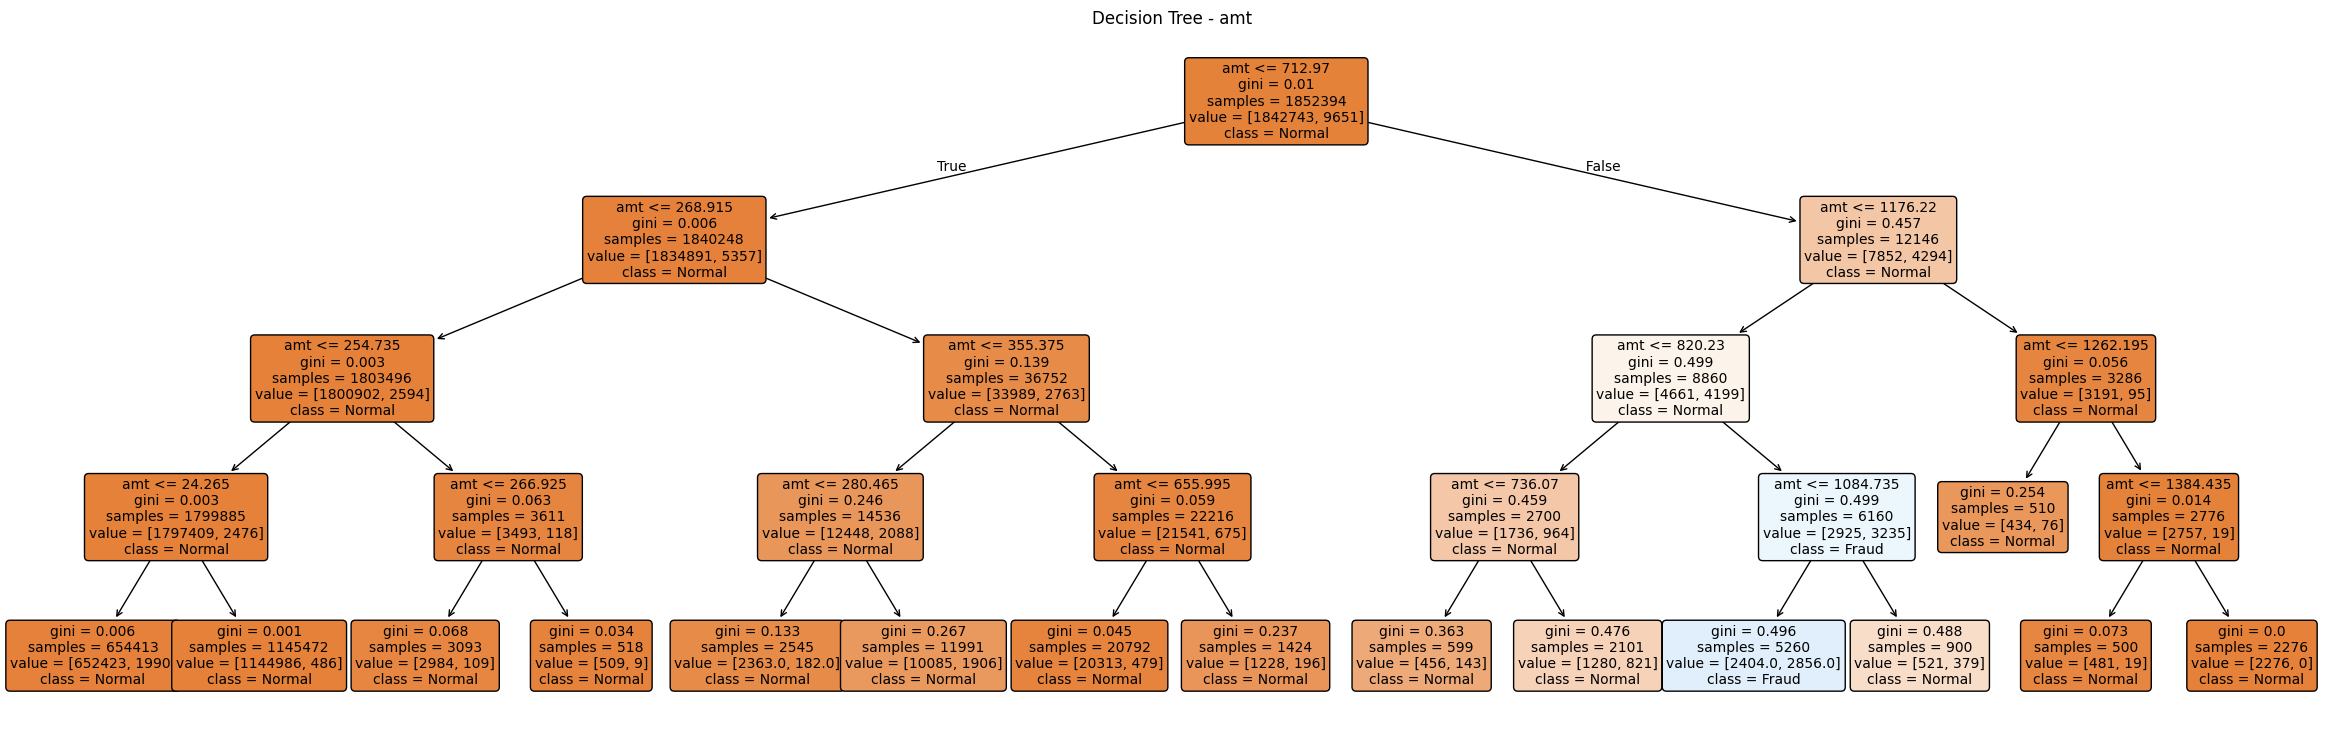


FRAUD RANGES
--------------------------------------------------------------------------------


,Feature,Leaf,Min,Max,Transactions,Normal,Fraud,Fraud_Rate
0,amt,4,1.00,24.26,"654,413","652,423","1,990",0.3041%
1,amt,5,24.27,254.73,"1,145,472","1,144,986",486,0.0424%
2,amt,7,254.74,266.92,"3,093","2,984",109,3.5241%
3,amt,8,266.93,268.91,518,509,9,1.7375%
4,amt,11,268.92,280.46,"2,545","2,363",182,7.1513%
5,amt,12,280.47,355.37,"11,991","10,085","1,906",15.8953%
6,amt,14,355.38,655.99,"20,792","20,313",479,2.3038%
7,amt,15,656.00,712.94,"1,424","1,228",196,13.7640%
8,amt,19,713.00,735.98,599,456,143,23.8731%
9,amt,20,736.16,820.21,"2,101","1,280",821,39.0766%


In [13]:
tree_amt, result_amt = analyze_feature(
    df,
    feature="amt",
    target="is_fraud",
    max_depth=4,
    min_samples_leaf=500
)

Fraud Rate
   ↑
55% |                         █
45% |                         █
40% |                    █    █
30% |
20% |              █    █
10% |        █      █
 0% | █ █                    █
   +--------------------------------→ amt
     کم       300   700   800  1000  1400+


DECISION TREE ANALYSIS: hour
Total transactions: 1,852,394
Fraud transactions: 9,651
Overall fraud rate: 0.5210%

TREE THRESHOLDS
--------------------------------------------------------------------------------
Node 0: hour <= 21.5000
Node 1: hour <= 3.5000
Node 2: hour <= 1.5000
Node 3: hour <= 0.5000
Node 6: hour <= 2.5000
Node 9: hour <= 5.5000
Node 10: hour <= 4.5000
Node 13: hour <= 13.5000
Node 16: hour <= 22.5000


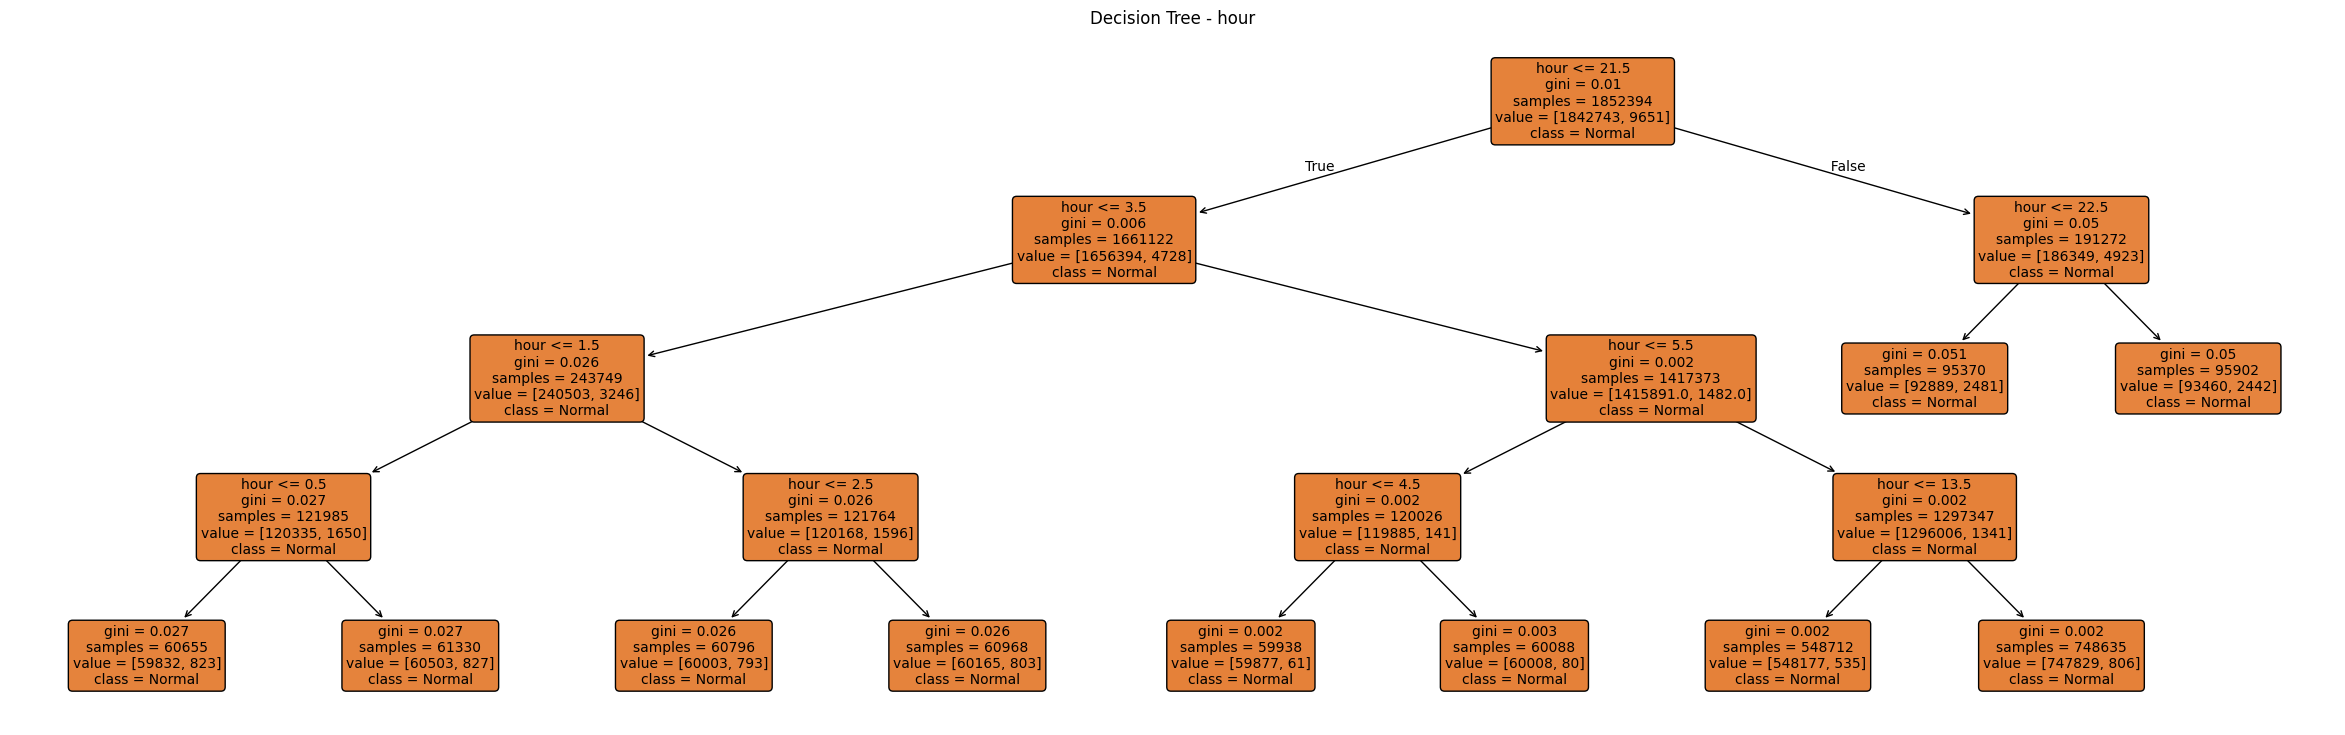


FRAUD RANGES
--------------------------------------------------------------------------------


,Feature,Leaf,Min,Max,Transactions,Normal,Fraud,Fraud_Rate
0,hour,4,0.00,0.00,"60,655","59,832",823,1.3569%
1,hour,5,1.00,1.00,"61,330","60,503",827,1.3484%
2,hour,7,2.00,2.00,"60,796","60,003",793,1.3044%
3,hour,8,3.00,3.00,"60,968","60,165",803,1.3171%
4,hour,11,4.00,4.00,"59,938","59,877",61,0.1018%
5,hour,12,5.00,5.00,"60,088","60,008",80,0.1331%
6,hour,14,6.00,13.00,"548,712","548,177",535,0.0975%
7,hour,15,14.00,21.00,"748,635","747,829",806,0.1077%
8,hour,17,22.00,22.00,"95,370","92,889","2,481",2.6014%
9,hour,18,23.00,23.00,"95,902","93,460","2,442",2.5463%


In [14]:
tree_hour, result_hour = analyze_feature(
    df,
    feature="hour",
    target="is_fraud",
    max_depth=4,
    min_samples_leaf=500
)

In [15]:

# ============================================================
# FUNCTION
# ============================================================

def analyze_amt_hour(df, target="is_fraud",
                     max_depth=5,
                     min_samples_leaf=1000):

    print("\n" + "=" * 90)
    print("DECISION TREE ANALYSIS: amt + hour")
    print("=" * 90)

    # فقط ستون‌های مورد نیاز
    data = df[["amt", "hour", target]].dropna().copy()

    X = data[["amt", "hour"]]
    y = data[target]

    print(f"Total transactions : {len(data):,}")
    print(f"Fraud transactions : {y.sum():,}")
    print(f"Overall fraud rate  : {y.mean() * 100:.4f}%")

    # ========================================================
    # DECISION TREE
    # ========================================================

    tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        criterion="gini",
        random_state=42
    )

    tree.fit(X, y)

    # ========================================================
    # TREE RULES
    # ========================================================

    print("\n" + "=" * 90)
    print("TREE RULES")
    print("=" * 90)

    rules = export_text(
        tree,
        feature_names=["amt", "hour"],
        decimals=2
    )

    print(rules)

    # ========================================================
    # PLOT TREE
    # ========================================================

    plt.figure(figsize=(22, 12))

    plot_tree(
        tree,
        feature_names=["amt", "hour"],
        class_names=["Normal", "Fraud"],
        filled=True,
        rounded=True,
        fontsize=9
    )

    plt.title("Decision Tree - amt + hour")
    plt.show()

    # ========================================================
    # FIND LEAVES
    # ========================================================

    data["leaf"] = tree.apply(X)

    results = []

    for leaf_id, group in data.groupby("leaf"):

        total = len(group)
        fraud = group[target].sum()
        normal = total - fraud

        fraud_rate = fraud / total * 100

        results.append({
            "Leaf": leaf_id,
            "Transactions": total,
            "Normal": normal,
            "Fraud": fraud,
            "Fraud_Rate": fraud_rate,

            "Min_amt": group["amt"].min(),
            "Max_amt": group["amt"].max(),

            "Min_hour": group["hour"].min(),
            "Max_hour": group["hour"].max()
        })

    result_df = pd.DataFrame(results)

    # مرتب‌سازی بر اساس Fraud Rate
    result_df = result_df.sort_values(
        "Fraud_Rate",
        ascending=False
    ).reset_index(drop=True)

    # ========================================================
    # RESULT
    # ========================================================

    print("\n" + "=" * 90)
    print("FRAUD RULES / LEAVES")
    print("=" * 90)

    display(
        result_df.style.format({
            "Transactions": "{:,}",
            "Normal": "{:,}",
            "Fraud": "{:,}",
            "Fraud_Rate": "{:.4f}%",
            "Min_amt": "{:.2f}",
            "Max_amt": "{:.2f}",
            "Min_hour": "{:.0f}",
            "Max_hour": "{:.0f}"
        })
    )

    return tree, result_df


DECISION TREE ANALYSIS: amt + hour
Total transactions : 1,852,394
Fraud transactions : 9,651
Overall fraud rate  : 0.5210%

TREE RULES
|--- amt <= 712.97
|   |--- amt <= 268.92
|   |   |--- hour <= 21.50
|   |   |   |--- hour <= 3.50
|   |   |   |   |--- amt <= 23.85
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- amt >  23.85
|   |   |   |   |   |--- class: 0
|   |   |   |--- hour >  3.50
|   |   |   |   |--- amt <= 228.96
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- amt >  228.96
|   |   |   |   |   |--- class: 0
|   |   |--- hour >  21.50
|   |   |   |--- amt <= 235.64
|   |   |   |   |--- amt <= 24.26
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- amt >  24.26
|   |   |   |   |   |--- class: 0
|   |   |   |--- amt >  235.64
|   |   |   |   |--- class: 0
|   |--- amt >  268.92
|   |   |--- hour <= 3.50
|   |   |   |--- amt <= 355.45
|   |   |   |   |--- amt <= 295.76
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- amt >  295.76
|   |   |   |   |   |-

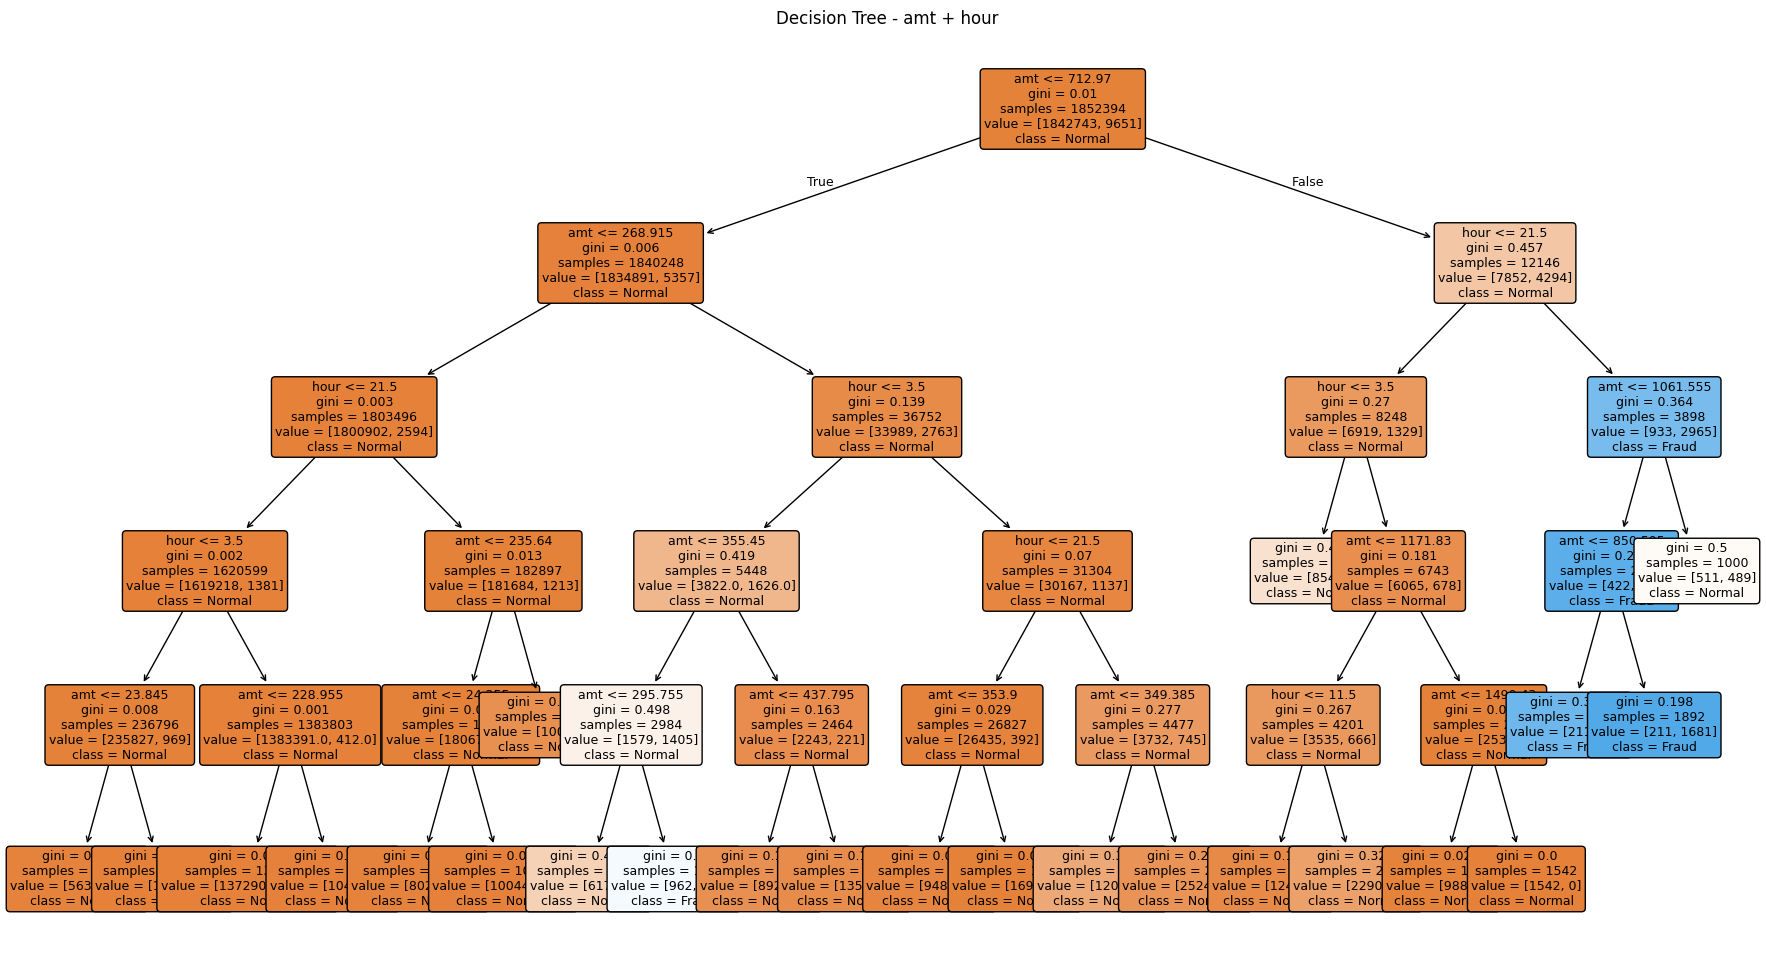


FRAUD RULES / LEAVES


,Leaf,Transactions,Normal,Fraud,Fraud_Rate,Min_amt,Max_amt,Min_hour,Max_hour
0,43,"1,892",211,"1,681",88.8478%,850.60,1061.53,22,23
1,42,"1,006",211,795,79.0258%,713.24,850.59,22,23
2,19,"1,977",962,"1,015",51.3404%,295.76,355.37,0,3
3,44,"1,000",511,489,48.9000%,1061.58,26544.12,22,23
4,32,"1,505",854,651,43.2558%,713.48,7747.73,0,3
5,18,"1,007",617,390,38.7289%,268.93,295.75,0,3
6,28,"1,586","1,208",378,23.8335%,268.96,349.38,22,23
7,36,"2,870","2,290",580,20.2091%,713.00,1171.78,12,21
8,29,"2,891","2,524",367,12.6946%,349.39,712.35,22,23
9,21,"1,000",892,108,10.8000%,355.53,437.65,0,3


In [16]:
tree_amt_hour, result_amt_hour = analyze_amt_hour(
    df,
    target="is_fraud",
    max_depth=5,
    min_samples_leaf=1000
)

# Models

In [18]:
features = [
    "amt",
    "hour",
    "city_pop",
    "lat",
    "long",
    "merch_lat",
    "merch_long",
    "time_diff_minutes"
]

target = "is_fraud"

In [19]:
data = df[features + [target]].dropna().copy()

X = data[features]
y = data[target]

print("Dataset shape:", X.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nFraud rate:")
print(f"{y.mean() * 100:.4f}%")

Dataset shape: (1851395, 8)

Class distribution:
is_fraud
0    1841835
1       9560
Name: count, dtype: int64

Fraud rate:
0.5164%


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTrain shape:", X_train.shape)
print("Test shape :", X_test.shape)


Train shape: (1481116, 8)
Test shape : (370279, 8)


## Random Forest

In [21]:


# ============================================================
# RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Prediction
rf_pred = rf_model.predict(X_test)

# Probability
rf_prob = rf_model.predict_proba(X_test)[:, 1]


# ============================================================
# EVALUATION
# ============================================================

print("=" * 70)
print("RANDOM FOREST")
print("=" * 70)

print(f"Accuracy : {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"F1       : {f1_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, rf_prob):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST
Accuracy : 0.9969
Precision: 0.7869
Recall   : 0.5350
F1       : 0.6370
ROC-AUC  : 0.9736

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    368367
       Fraud       0.79      0.54      0.64      1912

    accuracy                           1.00    370279
   macro avg       0.89      0.77      0.82    370279
weighted avg       1.00      1.00      1.00    370279

Confusion Matrix:
[[368090    277]
 [   889   1023]]


## AdaBoost

In [22]:
ada_model = AdaBoostClassifier(
    n_estimators=200,
    learning_rate=0.1,
    random_state=42
)

# Train
ada_model.fit(X_train, y_train)

# Prediction
ada_pred = ada_model.predict(X_test)

# Probability
ada_prob = ada_model.predict_proba(X_test)[:, 1]


# ============================================================
# EVALUATION
# ============================================================

print("=" * 70)
print("ADABOOST")
print("=" * 70)

print(f"Accuracy : {accuracy_score(y_test, ada_pred):.4f}")
print(f"Precision: {precision_score(y_test, ada_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, ada_pred, zero_division=0):.4f}")
print(f"F1       : {f1_score(y_test, ada_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, ada_prob):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        ada_pred,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, ada_pred))

ADABOOST
Accuracy : 0.9948
Precision: 0.0000
Recall   : 0.0000
F1       : 0.0000
ROC-AUC  : 0.9708

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00    368367
       Fraud       0.00      0.00      0.00      1912

    accuracy                           0.99    370279
   macro avg       0.50      0.50      0.50    370279
weighted avg       0.99      0.99      0.99    370279

Confusion Matrix:
[[368367      0]
 [  1912      0]]


## XGBoost

In [23]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

# Prediction
xgb_pred = xgb_model.predict(X_test)

# Probability
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]


# ============================================================
# EVALUATION
# ============================================================

print("=" * 70)
print("XGBOOST")
print("=" * 70)

print(f"Accuracy : {accuracy_score(y_test, xgb_pred):.4f}")
print(f"Precision: {precision_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"F1       : {f1_score(y_test, xgb_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, xgb_prob):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

XGBOOST
Accuracy : 0.9967
Precision: 0.7779
Recall   : 0.4927
F1       : 0.6033
ROC-AUC  : 0.9892

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    368367
       Fraud       0.78      0.49      0.60      1912

    accuracy                           1.00    370279
   macro avg       0.89      0.75      0.80    370279
weighted avg       1.00      1.00      1.00    370279

Confusion Matrix:
[[368098    269]
 [   970    942]]


## Threshold Tuning

In [24]:
# ============================================================
# THRESHOLDS
# ============================================================

thresholds = np.arange(0.05, 0.51, 0.05)


# ============================================================
# FUNCTION
# ============================================================

def threshold_analysis(y_true, probabilities, model_name):

    results = []

    for threshold in thresholds:

        # تبدیل probability به 0/1
        predictions = (probabilities >= threshold).astype(int)

        # Confusion Matrix
        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions
        ).ravel()

        # Metrics
        accuracy = accuracy_score(
            y_true,
            predictions
        )

        precision = precision_score(
            y_true,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_true,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            predictions,
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "True_Negative": tn,
            "False_Positive": fp,
            "False_Negative": fn,
            "True_Positive": tp
        })

    return pd.DataFrame(results)


# ============================================================
# RANDOM FOREST
# ============================================================

rf_thresholds = threshold_analysis(
    y_test,
    rf_prob,
    "Random Forest"
)


# ============================================================
# ADABOOST
# ============================================================

ada_thresholds = threshold_analysis(
    y_test,
    ada_prob,
    "AdaBoost"
)


# ============================================================
# XGBOOST
# ============================================================

xgb_thresholds = threshold_analysis(
    y_test,
    xgb_prob,
    "XGBoost"
)


# ============================================================
# COMBINE
# ============================================================

threshold_results = pd.concat(
    [
        rf_thresholds,
        ada_thresholds,
        xgb_thresholds
    ],
    ignore_index=True
)


# ============================================================
# DISPLAY
# ============================================================

display(
    threshold_results.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

,Model,Threshold,Accuracy,Precision,Recall,F1,True_Negative,False_Positive,False_Negative,True_Positive
0,Random Forest,0.05,0.9844,0.2283,0.8509,0.3600,362868,5499,285,1627
1,Random Forest,0.10,0.9913,0.3497,0.7897,0.4848,365559,2808,402,1510
2,Random Forest,0.15,0.9937,0.4324,0.7348,0.5445,366523,1844,507,1405
3,Random Forest,0.20,0.9949,0.5051,0.6993,0.5865,367057,1310,575,1337
4,Random Forest,0.25,0.9957,0.5732,0.6653,0.6158,367420,947,640,1272
5,Random Forest,0.30,0.9961,0.6202,0.6328,0.6265,367626,741,702,1210
6,Random Forest,0.35,0.9964,0.6674,0.6109,0.6379,367785,582,744,1168
7,Random Forest,0.40,0.9966,0.7055,0.5889,0.6420,367897,470,786,1126
8,Random Forest,0.45,0.9968,0.7491,0.5622,0.6424,368007,360,837,1075
9,Random Forest,0.50,0.9969,0.7869,0.5350,0.6370,368090,277,889,1023


In [25]:
# ============================================================
# BEST THRESHOLD BY F1
# ============================================================

best_thresholds = (
    threshold_results
    .sort_values(
        ["Model", "F1"],
        ascending=[True, False]
    )
    .groupby("Model")
    .head(1)
    .reset_index(drop=True)
)

print("=" * 80)
print("BEST THRESHOLD FOR EACH MODEL")
print("=" * 80)

display(
    best_thresholds.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

BEST THRESHOLD FOR EACH MODEL


,Model,Threshold,Accuracy,Precision,Recall,F1,True_Negative,False_Positive,False_Negative,True_Positive
0,AdaBoost,0.45,0.9958,0.6751,0.3750,0.4822,368022,345,1195,717
1,Random Forest,0.45,0.9968,0.7491,0.5622,0.6424,368007,360,837,1075
2,XGBoost,0.30,0.9963,0.6589,0.5952,0.6254,367778,589,774,1138


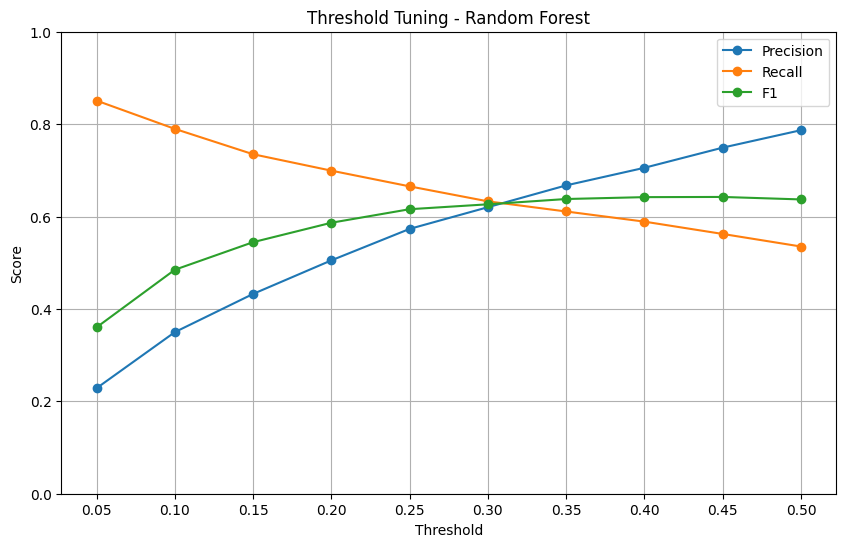

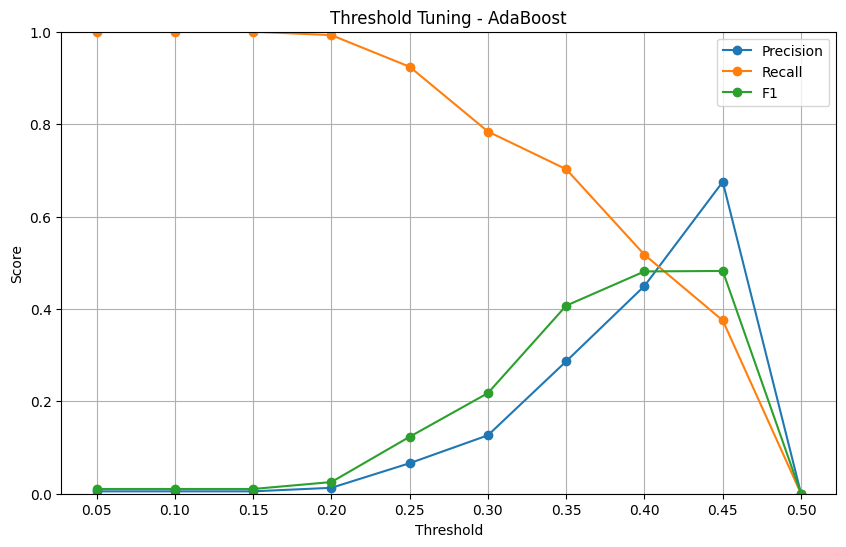

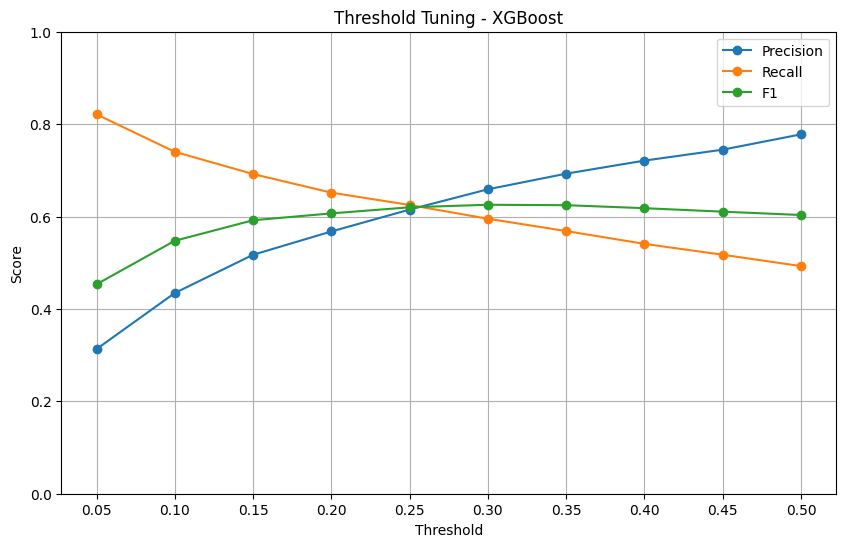

In [26]:
models_to_plot = [
    ("Random Forest", rf_thresholds),
    ("AdaBoost", ada_thresholds),
    ("XGBoost", xgb_thresholds)
]


for model_name, results in models_to_plot:

    plt.figure(figsize=(10, 6))

    plt.plot(
        results["Threshold"],
        results["Precision"],
        marker="o",
        label="Precision"
    )

    plt.plot(
        results["Threshold"],
        results["Recall"],
        marker="o",
        label="Recall"
    )

    plt.plot(
        results["Threshold"],
        results["F1"],
        marker="o",
        label="F1"
    )

    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Threshold Tuning - {model_name}")

    plt.xticks(thresholds)
    plt.ylim(0, 1)

    plt.grid(True)
    plt.legend()

    plt.show()

## Feature Importance 

In [27]:

# ساخت DataFrame برای Feature Importance
feature_importance = pd.DataFrame({
    "Feature": features,
    "Random Forest": rf_model.feature_importances_,
    "AdaBoost": ada_model.feature_importances_,
    "XGBoost": xgb_model.feature_importances_
})

# مرتب‌سازی بر اساس میانگین اهمیت سه مدل
feature_importance["Mean"] = feature_importance[
    ["Random Forest", "AdaBoost", "XGBoost"]
].mean(axis=1)

feature_importance = feature_importance.sort_values(
    "Mean", ascending=False
)

# نمایش جدول
print(feature_importance)

             Feature  Random Forest  AdaBoost   XGBoost      Mean
0                amt       0.567609  0.789047  0.401315  0.585991
1               hour       0.218275  0.197334  0.434086  0.283232
7  time_diff_minutes       0.086572  0.013618  0.076580  0.058923
2           city_pop       0.027180  0.000000  0.023597  0.016926
3                lat       0.023094  0.000000  0.019457  0.014184
6         merch_long       0.027428  0.000000  0.014087  0.013838
5          merch_lat       0.027405  0.000000  0.013384  0.013596
4               long       0.022437  0.000000  0.017494  0.013311


Feature importance analysis across Random Forest, AdaBoost, and XGBoost showed that transaction amount (amt) was the most influential feature, followed by transaction hour (hour). Time difference between transactions also provided meaningful predictive information, while geographic features such as latitude, longitude, and city population had considerably lower importance.